<a href="https://colab.research.google.com/github/yashita-mishra/AI-Project-Child-Nutrition/blob/main/02_features_and_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 - Feature table and Data Analysis
- `data/children_model.csv`: one discrete column per DAG node plus the blood features. Gaps are now NaN.
- `data/children_complete.csv`: complete cases on the DAG nodes.
- `figures/*.png`: distributions, correlations, anaemia by node.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

NAME = "children_2_6_renamed.csv"
RAW = "https://raw.githubusercontent.com/yashita-mishra/AI-Project-Child-Nutrition/main/" + NAME
df = pd.read_csv(NAME if os.path.exists(NAME) else RAW)
print(df.shape)

(664, 61)


## 1. Fix SAS zeros
`read_sas` stores exact zeros as ~5e-79, so the `== 0` checks in `Nhanescleanup.ipynb` never matched and the "still / never" flags are all False. This cell is safe to run even after the cleanup notebook is fixed.

In [3]:
num = df.select_dtypes("number").columns
df[num] = df[num].mask(df[num].abs() < 1e-10, 0)
df["id"] = df["id"].astype(int)

ZERO_FLAGS = {
    "breastfeed_stop_days": "still_breastfeeding",
    "formula_start_days": "formula_never",
    "formula_stop_days": "still_formula",
    "first_other_food_days": "other_food_never",
    "first_milk_days": "milk_never",
}
for col, flag in ZERO_FLAGS.items():
    df[flag] = df[col] == 0
    df[col] = df[col].replace(0, np.nan)
print({f: int(df[f].sum()) for f in ZERO_FLAGS.values()})   # expect 6, 142, 6, 0, 18

{'still_breastfeeding': 6, 'formula_never': 142, 'still_formula': 6, 'other_food_never': 0, 'milk_never': 18}


## 2. Blood features
Hemoglobin and hematocrit correlate at 0.93, so they are compacted into: `hb_margin` (g/dL above the age-specific WHO cutoff), `anaemia`, `hb_level`, `anaemia_severity` and `mchc` (descriptive only, not a network node).

In [4]:
cutoff = np.where(df["age_years"] < 5, 11.0, 11.5)
df["hb_margin"] = df["hemoglobin_gdl"] - cutoff
df["anaemia"] = np.where(df["hb_margin"].notna(), (df["hb_margin"] < 0).astype(float), np.nan)
df["hb_level"] = pd.cut(df["hb_margin"], [-9, 0, 1, 9], right=False,
                        labels=["anaemic", "borderline", "normal"])
hb = df["hemoglobin_gdl"]
sev = np.where(df["age_years"] < 5,
               np.select([hb < 7, hb < 10, hb < 11], [3, 2, 1], 0),
               np.select([hb < 8, hb < 11, hb < 11.5], [3, 2, 1], 0))
df["anaemia_severity"] = np.where(hb.notna(), sev, np.nan)       # 0 none, 1 mild, 2 moderate, 3 severe
df["mchc"] = 100 * hb / df["hematocrit_pct"]
print(df["hb_level"].value_counts(dropna=False).to_dict())

{nan: 324, 'normal': 196, 'borderline': 120, 'anaemic': 24}


## 3. DAG node table
One discrete column per node of the DAG. Gaps stay NaN (EM handles them later). Structural gaps are recoded: never-SNAP households are "no", and child WIC stays blank for 6-year-olds because it was not asked.

In [5]:
m = pd.DataFrame({"id": df["id"], "age_years": df["age_years"].astype(int), "sex": df["sex"]})
m["ethnicity"] = df["ethnicity"]
m["parent_edu"] = df["parent_edu"].map({1: "low", 2: "mid", 3: "high"})
m["income"] = pd.cut(df["income_poverty_ratio"], [-0.01, 1, 1.85, 5.01],
                     labels=["below_poverty", "to_185pct", "above_185pct"])
m["wic_child"] = df["child_ever_wic"].map({1: "yes", 2: "no"})
m["snap_past_year"] = np.where(df["hh_snap_ever"] == 2, "no",
                      np.where(df["hh_snap_ever"] == 1,
                               np.where(df["hh_snap_past_year"] == 1, "yes", "no"), None))
m["food_security"] = df["adult_food_security"].map({1: "secure", 2: "secure", 3: "insecure", 4: "insecure"})
m["ever_breastfed"] = df["ever_breastfed"].map({1: "yes", 2: "no"})
m["milk_before_12m"] = np.where(df["first_milk_days"].notna(),
                                np.where(df["first_milk_days"] < 365, "yes", "no"),
                                np.where(df["milk_never"], "no", None))
m["low_birth_weight"] = df["low_birth_weight"].map({0.0: "no", 1.0: "yes"})
m["anaemia"] = df["anaemia"].map({0.0: "no", 1.0: "yes"})
m["hb_level"] = df["hb_level"].astype("object")
m["hb_margin"] = df["hb_margin"]
m["mchc"] = df["mchc"]
m["anaemia_severity"] = df["anaemia_severity"]
m["weight_exam"] = df["weight_exam"]            # survey weight, for population estimates

NODES = ["ethnicity", "parent_edu", "income", "wic_child", "snap_past_year", "food_security",
         "ever_breastfed", "milk_before_12m", "low_birth_weight", "anaemia"]
m.to_csv("data/children_model.csv", index=False)
complete = m.dropna(subset=NODES)
complete.to_csv("data/children_complete.csv", index=False)
print("model table:", m.shape, " complete cases on nodes:", len(complete))
m[NODES].apply(lambda s: s.value_counts(dropna=False).to_dict())

model table: (664, 18)  complete cases on nodes: 211


,0
ethnicity,"{3.0: 275, 4.0: 105, 2.0: 102, 1.0: 82, 7.0: 5..."
parent_edu,"{'mid': 297, 'high': 212, nan: 80, 'low': 75}"
income,"{'above_185pct': 290, 'below_poverty': 159, 't..."
wic_child,"{'yes': 304, 'no': 235, nan: 125}"
snap_past_year,"{'no': 338, 'yes': 268, None: 58}"
food_security,"{'secure': 462, 'insecure': 145, nan: 57}"
ever_breastfed,"{'yes': 532, 'no': 130, nan: 2}"
milk_before_12m,"{'no': 456, 'yes': 185, None: 23}"
low_birth_weight,"{'no': 603, 'yes': 59, nan: 2}"
anaemia,"{nan: 324, 'no': 316, 'yes': 24}"


## 4. Distributions

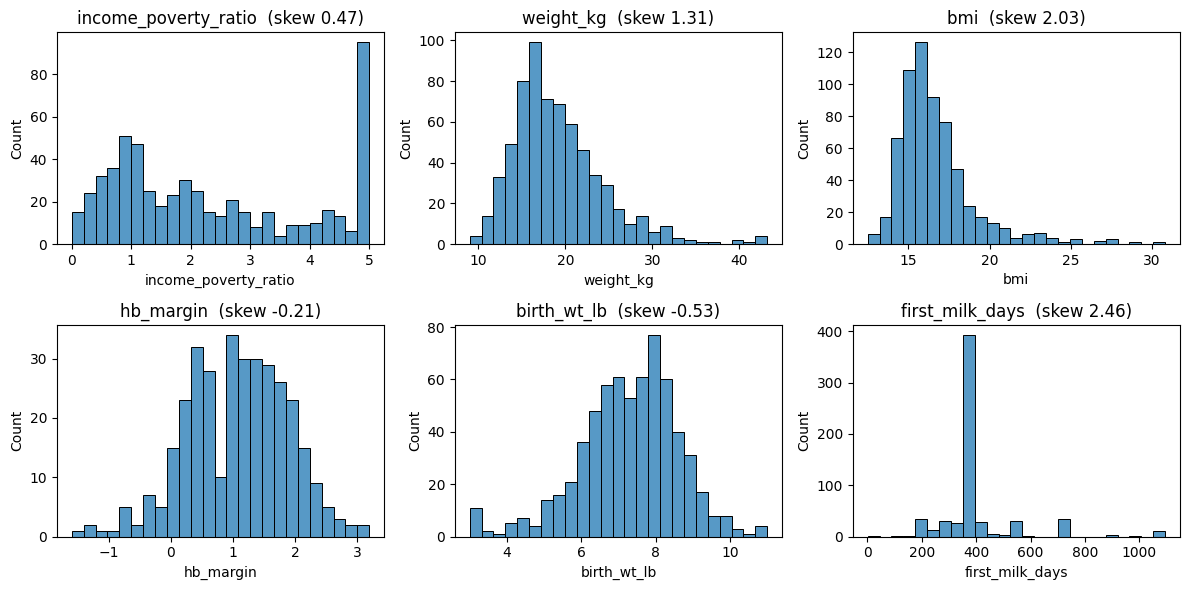

income at the cap of 5: 91 | first_milk exactly 365 days: 318


In [6]:
cols = ["income_poverty_ratio", "weight_kg", "bmi", "hb_margin", "birth_wt_lb", "first_milk_days"]
fig, ax = plt.subplots(2, 3, figsize=(12, 6))
for a, c in zip(ax.ravel(), cols):
    sns.histplot(df[c].dropna(), bins=25, ax=a)
    a.set_title(f"{c}  (skew {df[c].skew():.2f})")
plt.tight_layout(); plt.savefig("figures/distributions.png", dpi=130); plt.show()
print("income at the cap of 5:", int((df.income_poverty_ratio == 5).sum()),
      "| first_milk exactly 365 days:", int((df.first_milk_days == 365).sum()))

## 5. Correlations (Spearman)

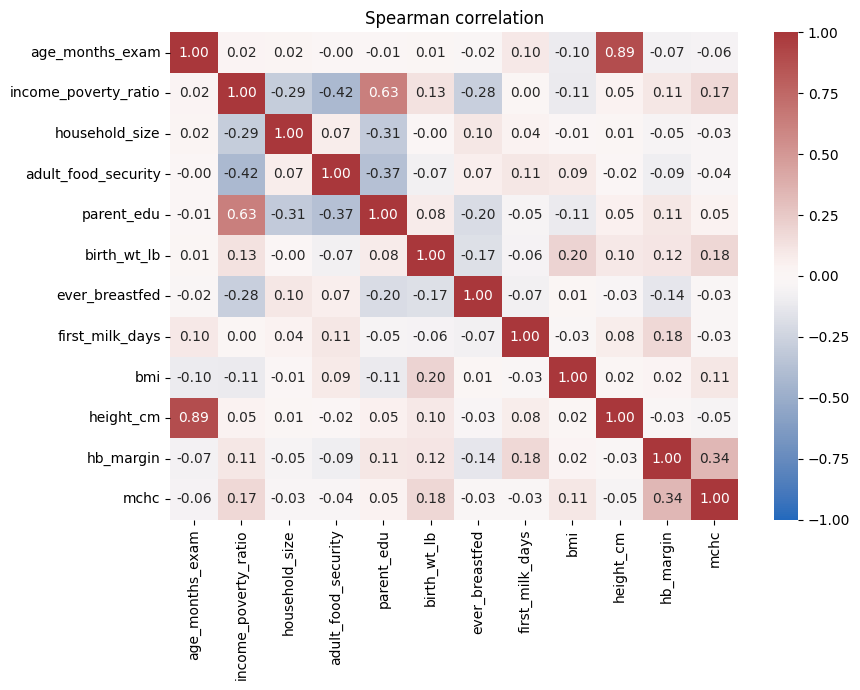

In [7]:
n = ["age_months_exam", "income_poverty_ratio", "household_size", "adult_food_security", "parent_edu",
     "birth_wt_lb", "ever_breastfed", "first_milk_days", "bmi", "height_cm", "hb_margin", "mchc"]
S = df[n].corr("spearman")
plt.figure(figsize=(9, 7))
sns.heatmap(S, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation"); plt.tight_layout()
plt.savefig("figures/correlation.png", dpi=130); plt.show()

## 6. Anaemia and continuous hemoglobin against each node

In [8]:
d = m[m.anaemia.notna()]
rows = []
for c in NODES[:-1]:
    x = d[[c, "anaemia"]].dropna()
    ct = pd.crosstab(x[c], x["anaemia"])
    rows.append({"node": c, "n": len(x), "p_chi2_anaemia": round(stats.chi2_contingency(ct)[1], 3),
                 "anaemia_rate_by_level": (ct["yes"] / ct.sum(axis=1)).round(3).to_dict()})
g = m[m.hb_margin.notna()]
for r in rows:
    x = g[[r["node"], "hb_margin"]].dropna()
    groups = [v.hb_margin.values for _, v in x.groupby(r["node"], observed=True)]
    r["p_kruskal_hb_margin"] = round(stats.kruskal(*groups)[1], 4)
pd.DataFrame(rows).set_index("node")

,n,p_chi2_anaemia,anaemia_rate_by_level,p_kruskal_hb_margin
node,,,,
ethnicity,340,0.002,"{1.0: 0.026, 2.0: 0.155, 3.0: 0.029, 4.0: 0.15...",0.0000
parent_edu,303,0.148,"{'high': 0.037, 'low': 0.024, 'mid': 0.086}",0.1538
income,299,0.013,"{'below_poverty': 0.136, 'to_185pct': 0.031, '...",0.0983
wic_child,263,0.067,"{'no': 0.035, 'yes': 0.101}",0.0301
snap_past_year,317,0.297,"{'no': 0.051, 'yes': 0.086}",0.0184
food_security,317,0.026,"{'insecure': 0.127, 'secure': 0.046}",0.0739
ever_breastfed,338,0.996,"{'no': 0.076, 'yes': 0.066}",0.0112
milk_before_12m,330,0.479,"{'no': 0.064, 'yes': 0.094}",0.0021
low_birth_weight,338,0.869,"{'no': 0.069, 'yes': 0.094}",0.5662


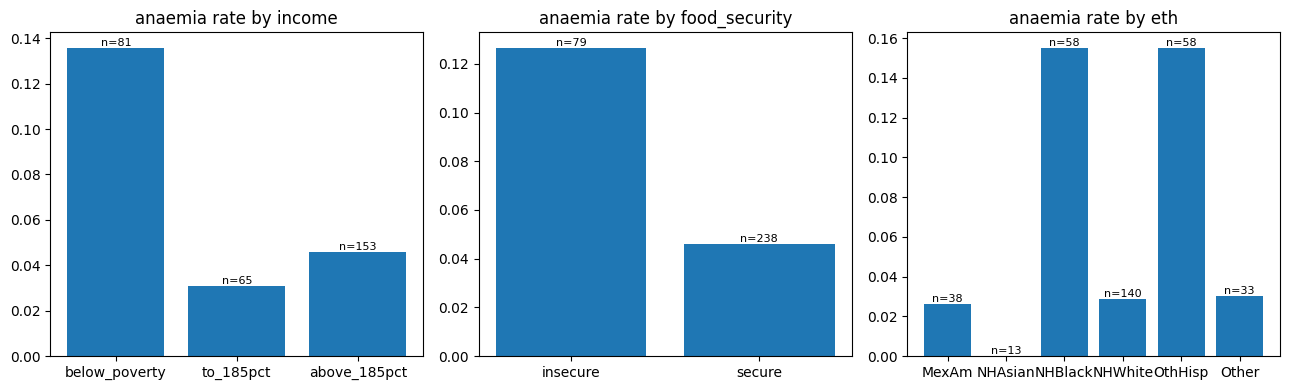

In [9]:
lab = {1: "MexAm", 2: "OthHisp", 3: "NHWhite", 4: "NHBlack", 6: "NHAsian", 7: "Other"}
d = d.assign(eth=d.ethnicity.map(lab))
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, c in zip(ax, ["income", "food_security", "eth"]):
    t = d.assign(y=(d.anaemia == "yes")).groupby(c, observed=True).y.agg(["mean", "count"])
    a.bar(t.index.astype(str), t["mean"]); a.set_title(f"anaemia rate by {c}")
    for i, (mu, k) in enumerate(zip(t["mean"], t["count"])):
        a.text(i, mu, f"n={k}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.savefig("figures/anaemia_by_node.png", dpi=130); plt.show()

## 7. Missingness: is it random?
Income, parent education and the blood draw are not missing completely at random: blood is missing more for younger children and for the Asian group, and parent education gaps relate to income, food security and birth weight. That is consistent with missing at random given observed variables, so complete-case deletion is biased and EM (or multiple imputation) is the right tool. Do not impute the anaemia label.

In [10]:
def miss_tests(target, others):
    out = {}
    for c in others:
        x = pd.DataFrame({"miss": m[target].isna(), "v": m[c]}).dropna()
        t = pd.crosstab(x["v"], x["miss"])
        if t.shape[0] > 1 and t.shape[1] > 1:
            p = stats.chi2_contingency(t)[1]
            if p < 0.05:
                out[c] = float(round(p, 3))
    return out
for tgt in ["income", "parent_edu", "anaemia", "food_security", "wic_child"]:
    print(tgt, miss_tests(tgt, ["age_years", "sex"] + [c for c in NODES if c != tgt]))

income {'ethnicity': 0.026}
parent_edu {'ethnicity': 0.014, 'income': 0.017, 'food_security': 0.002, 'low_birth_weight': 0.002, 'anaemia': 0.05}
anaemia {'age_years': 0.045, 'ethnicity': 0.045}
food_security {'ethnicity': 0.015}
wic_child {'age_years': 0.0}


## 8. Data-driven network: probabilities from the observed rows only, then redraw the DAG
Nothing is imputed here. Every probability below is a **count of the children who actually have that answer**:
- a node's table P(node | parents) uses only rows where the node *and* all its parents are observed;
- a parent combination nobody falls into stays **NaN ("no data")**, not 0 and not a guess. Those are exactly the cells EM will fill in section 9;
- the DAG is redrawn from these numbers: arrow thickness = strength of association in the data, dashed = not supported by the data (kept only because of domain knowledge).

**Structure change:** `ethnicity -> anaemia` is added (chi-square p = 0.002 in section 6).

In [14]:
#8.1 network definition (uses the node names of section 3)
from itertools import product

ETH = {1: "MexAm", 2: "OthHisp", 3: "NHWhite", 4: "NHBlack", 6: "Asian_Other", 7: "Asian_Other"}
net = m[NODES].copy()
net["ethnicity"] = net["ethnicity"].map(ETH)            # codes 6 and 7 merged (small groups)
net = net.astype(object).where(net.notna(), np.nan)

STATES = {
    "ethnicity":        ["MexAm", "OthHisp", "NHWhite", "NHBlack", "Asian_Other"],
    "parent_edu":       ["low", "mid", "high"],
    "income":           ["below_poverty", "to_185pct", "above_185pct"],
    "wic_child":        ["no", "yes"],
    "snap_past_year":   ["no", "yes"],
    "food_security":    ["secure", "insecure"],
    "ever_breastfed":   ["no", "yes"],
    "milk_before_12m":  ["no", "yes"],
    "low_birth_weight": ["no", "yes"],
    "anaemia":          ["no", "yes"],
}
EDGES = [
    ("ethnicity", "income"), ("parent_edu", "income"),
    ("parent_edu", "ever_breastfed"), ("parent_edu", "milk_before_12m"),
    ("income", "low_birth_weight"),
    ("income", "snap_past_year"), ("income", "wic_child"),
    ("income", "food_security"), ("snap_past_year", "food_security"), ("wic_child", "food_security"),
    ("ethnicity", "anaemia"),                                   # NEW
    ("food_security", "anaemia"), ("wic_child", "anaemia"),
    ("low_birth_weight", "anaemia"), ("ever_breastfed", "anaemia"), ("milk_before_12m", "anaemia"),
]
PARENTS = {n: [u for u, v in EDGES if v == n] for n in NODES}
assert set(STATES) == set(NODES)
for n in NODES:                                          # every observed value must be a declared state
    bad = set(net[n].dropna()) - set(STATES[n])
    assert not bad, (n, bad)
print({n: PARENTS[n] for n in NODES if PARENTS[n]})

{'income': ['ethnicity', 'parent_edu'], 'wic_child': ['income'], 'snap_past_year': ['income'], 'food_security': ['income', 'snap_past_year', 'wic_child'], 'ever_breastfed': ['parent_edu'], 'milk_before_12m': ['parent_edu'], 'low_birth_weight': ['income'], 'anaemia': ['ethnicity', 'food_security', 'wic_child', 'low_birth_weight', 'ever_breastfed', 'milk_before_12m']}


In [15]:
#8.2 conditional probability tables from the rows that have data
THIN = 5          # parent combinations with fewer rows than this are flagged "thin"

def cpt_counts(node, parents=None):
    """Counts and P(node | parents) using only rows where node and all parents are observed."""
    parents = PARENTS[node] if parents is None else parents
    sub = net[[node] + parents].dropna()
    if parents:
        idx = pd.MultiIndex.from_product([STATES[p] for p in parents], names=parents)
        cnt = (sub.groupby(parents + [node]).size().unstack(node)
                  .reindex(index=idx, columns=STATES[node]).fillna(0).astype(int))
    else:
        cnt = pd.DataFrame([sub[node].value_counts().reindex(STATES[node]).fillna(0).astype(int)])
    n = cnt.sum(axis=1)
    prob = cnt.div(n.where(n > 0), axis=0)                 # n == 0  ->  NaN  ("no data")
    return cnt, prob, n, len(sub)

CPT = {}
rows = []
for node in NODES:
    cnt, prob, n, used = cpt_counts(node)
    CPT[node] = dict(counts=cnt, prob=prob, n=n)
    k = len(cnt)
    rows.append({"node": node, "parents": ", ".join(PARENTS[node]) or "-", "rows_used": used,
                 "parent_combos": k, "combos_with_data": int((n > 0).sum()),
                 "combos_n>=5": int((n >= THIN).sum()),
                 "share_of_rows_in_thin_combos": round(float(n[(n > 0) & (n < THIN)].sum() / max(used, 1)), 2)})
coverage = pd.DataFrame(rows).set_index("node")
coverage

,parents,rows_used,parent_combos,combos_with_data,combos_n>=5,share_of_rows_in_thin_combos
node,,,,,,
ethnicity,-,664,1,1,1,0.00
parent_edu,-,584,1,1,1,0.00
income,"ethnicity, parent_edu",525,15,15,15,0.00
wic_child,income,474,3,0,0,0.00
snap_past_year,income,573,3,0,0,0.00
food_security,"income, snap_past_year, wic_child",473,12,12,12,0.00
ever_breastfed,parent_edu,582,3,0,0,0.00
milk_before_12m,parent_edu,564,3,0,0,0.00
low_birth_weight,income,573,3,0,0,0.00


In [16]:
#8.3 the anaemia table: where does the data actually exist?
a = CPT["anaemia"]
tab = a["counts"].assign(n=a["n"], P_anaemia_yes=a["prob"]["yes"].round(3))
tab = tab[tab.n > 0].sort_values("n", ascending=False)
print(f"{len(tab)} of {len(a['counts'])} parent combinations have any data; "
      f"{int((tab.n >= THIN).sum())} have {THIN}+ children; "
      f"{int(a['counts']['yes'].sum())} anaemic children in total")
tab.head(15)

66 of 160 parent combinations have any data; 13 have 5+ children; 17 anaemic children in total


anaemia                                                                              no  \
ethnicity   food_security wic_child low_birth_weight ever_breastfed milk_before_12m       
NHWhite     secure        no        no               yes            no               37   
                                                                    yes              18   
OthHisp     insecure      yes       no               yes            no               11   
NHWhite     secure        yes       no               yes            no               10   
NHBlack     secure        yes       no               yes            no               10   
MexAm       secure        no        no               yes            no                8   
OthHisp     secure        yes       no               yes            yes               6   
                                                                    no                7   
Asian_Other secure        yes       no               no             no                6   
NHBlack     insecure      yes       no               yes            no                5   
OthHisp     secure        no        no               yes            no                4   
Asian_Other secure        no        no               yes            no                5   
NHWhite     secure        yes       no               yes            yes               5   
            insecure      yes       no               yes            no                4   
            secure        no        no               no             no                4   

anaemia                                                                              yes  \
ethnicity   food_security wic_child low_birth_weight ever_breastfed milk_before_12m        
NHWhite     secure        no        no               yes            no                 1   
                                                                    yes                0   
OthHisp     insecure      yes       no               yes            no                 3   
NHWhite     secure        yes       no               yes            no                 1   
NHBlack     secure        yes       no               yes            no                 0   
MexAm       secure        no        no               yes            no                 0   
OthHisp     secure        yes       no               yes            yes                2   
                                                                    no                 0   
Asian_Other secure        yes       no               no             no                 0   
NHBlack     insecure      yes       no               yes            no                 0   
OthHisp     secure        no        no               yes            no                 1   
Asian_Other secure        no        no               yes            no                 0   
NHWhite     secure        yes       no               yes            yes                0   
            insecure      yes       no               yes            no                 0   
            secure        no        no               no             no                 0   

anaemia                                                                               n  \
ethnicity   food_security wic_child low_birth_weight ever_breastfed milk_before_12m       
NHWhite     secure        no        no               yes            no               38   
                                                                    yes              18   
OthHisp     insecure      yes       no               yes            no               14   
NHWhite     secure        yes       no               yes            no               11   
NHBlack     secure        yes       no               yes            no               10   
MexAm       secure        no        no               yes            no                8   
OthHisp     secure        yes       no               yes            yes               8   
                                                                    

In [17]:
#8.4 per-edge evidence + node marginals, from pairwise-complete rows
def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); r, c = ct.shape
    phi2 = max(0.0, chi2 / n - (c - 1) * (r - 1) / (n - 1))          # bias-corrected
    rc, cc = r - (r - 1) ** 2 / (n - 1), c - (c - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / max(min(cc - 1, rc - 1), 1e-9)))

KEY = {"parent_edu": "low", "income": "below_poverty", "wic_child": "yes", "snap_past_year": "yes",
       "food_security": "insecure", "ever_breastfed": "yes", "milk_before_12m": "yes",
       "low_birth_weight": "yes", "anaemia": "yes"}                      # state shown inside each node

edge_rows = []
for u, v in EDGES:
    x = net[[u, v]].dropna()
    ct = pd.crosstab(x[u], x[v]).reindex(index=STATES[u], columns=STATES[v]).fillna(0)
    ct = ct.loc[ct.sum(axis=1) > 0, ct.sum(axis=0) > 0]
    chi2, p, _, exp = stats.chi2_contingency(ct)
    by_parent = (ct.div(ct.sum(axis=1), axis=0)[KEY[v]].round(3).to_dict() if v in KEY else {})
    edge_rows.append({"edge": f"{u} -> {v}", "u": u, "v": v, "n_pairs": int(ct.values.sum()),
                      "cramers_v": round(cramers_v(ct), 3), "p_chi2": round(p, 4),
                      "low_expected_counts": bool((exp < 5).any()),
                      f"P(child=key state | parent level)": by_parent})
edges = pd.DataFrame(edge_rows).set_index("edge")
edges["supported"] = edges["p_chi2"] < 0.05
edges.drop(columns=["u", "v"])

,n_pairs,cramers_v,p_chi2,low_expected_counts,P(child=key state | parent level),supported
edge,,,,,,
ethnicity -> income,575,0.277,0.0000,False,"{'MexAm': 0.344, 'OthHisp': 0.425, 'NHWhite': ...",True
parent_edu -> income,525,0.403,0.0000,False,"{'low': 0.694, 'mid': 0.321, 'high': 0.046}",True
parent_edu -> ever_breastfed,582,0.206,0.0000,False,"{'low': 0.733, 'mid': 0.747, 'high': 0.919}",True
parent_edu -> milk_before_12m,564,0.000,0.7326,False,"{'low': 0.288, 'mid': 0.291, 'high': 0.322}",False
income -> low_birth_weight,573,0.049,0.1846,False,"{'below_poverty': 0.119, 'to_185pct': 0.08, 'a...",False
income -> snap_past_year,573,0.550,0.0000,False,"{'below_poverty': 0.792, 'to_185pct': 0.597, '...",True
income -> wic_child,474,0.572,0.0000,False,"{'below_poverty': 0.89, 'to_185pct': 0.778, 'a...",True
income -> food_security,575,0.323,0.0000,False,"{'below_poverty': 0.403, 'to_185pct': 0.341, '...",True
snap_past_year -> food_security,605,0.187,0.0000,False,"{'no': 0.166, 'yes': 0.33}",True


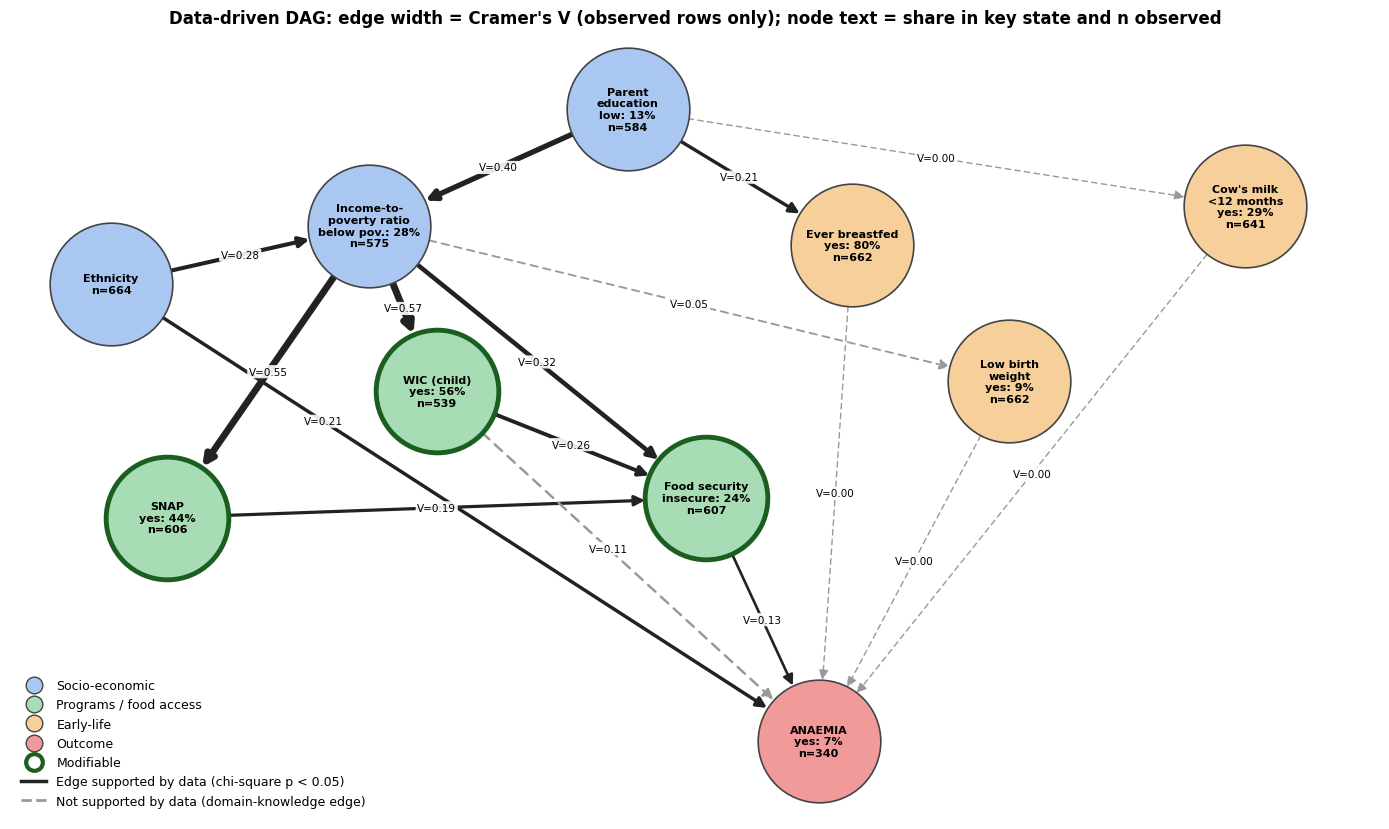

In [18]:
#8.5 redraw the DAG from the data
import networkx as nx
POS = {"ethnicity": (-0.3, 3.0), "parent_edu": (4.3, 4.8), "income": (2.0, 3.6),
       "ever_breastfed": (6.3, 3.4), "milk_before_12m": (9.8, 3.8), "low_birth_weight": (7.7, 2.0),
       "snap_past_year": (0.2, 0.6), "wic_child": (2.6, 1.9), "food_security": (5.0, 0.8),
       "anaemia": (6.0, -1.7)}
LABEL_T = {("ethnicity", "anaemia"): 0.3, ("wic_child", "anaemia"): 0.45}     # label position along the arrow
GROUP = {"ethnicity": "Socio-economic", "parent_edu": "Socio-economic", "income": "Socio-economic",
         "snap_past_year": "Programs / food access", "wic_child": "Programs / food access",
         "food_security": "Programs / food access", "ever_breastfed": "Early-life",
         "milk_before_12m": "Early-life", "low_birth_weight": "Early-life", "anaemia": "Outcome"}
COL = {"Socio-economic": "#a9c7f0", "Programs / food access": "#a8dcb4", "Early-life": "#f6cf9b", "Outcome": "#f09a9a"}
MODIFIABLE = {"snap_past_year", "wic_child", "food_security"}
SHORT = {"ethnicity": "Ethnicity", "parent_edu": "Parent\neducation", "income": "Income-to-\npoverty ratio",
         "snap_past_year": "SNAP", "wic_child": "WIC (child)", "food_security": "Food security",
         "ever_breastfed": "Ever breastfed", "milk_before_12m": "Cow's milk\n<12 months",
         "low_birth_weight": "Low birth\nweight", "anaemia": "ANAEMIA"}

KEY_SHORT = {"below_poverty": "below pov."}

def node_text(n):
    obs = int(net[n].notna().sum())
    if n in KEY:
        share = (net[n].dropna() == KEY[n]).mean()
        return f"{SHORT[n]}\n{KEY_SHORT.get(KEY[n], KEY[n])}: {share:.0%}\nn={obs}"
    return f"{SHORT[n]}\nn={obs}"

def draw_dag(edge_list=None, path="figures/dag_data_driven.png", title=None):
    G = nx.DiGraph(edge_list if edge_list is not None else EDGES)
    fig, ax = plt.subplots(figsize=(14, 8.4)); ax.axis("off")
    for (u, v) in G.edges:
        e = edges.loc[f"{u} -> {v}"]
        ok = bool(e.supported)
        rad = 0.0
        nx.draw_networkx_edges(G, POS, edgelist=[(u, v)], ax=ax, node_size=7800, arrowsize=15,
                               width=1 + 7 * e.cramers_v, style="solid" if ok else (0, (4, 3)),
                               edge_color="#222" if ok else "#999",
                               connectionstyle=f"arc3,rad={rad}")
    for n in G.nodes:
        nx.draw_networkx_nodes(G, POS, nodelist=[n], node_size=7800, node_color=COL[GROUP[n]], ax=ax,
                               edgecolors="#1b5e20" if n in MODIFIABLE else "#444",
                               linewidths=3.5 if n in MODIFIABLE else 1.2)
    nx.draw_networkx_labels(G, POS, labels={n: node_text(n) for n in G.nodes}, font_size=8,
                            font_weight="bold", ax=ax)
    # edge labels along each arrow
    for (u, v) in G.edges:
        e = edges.loc[f"{u} -> {v}"]
        (x0, y0), (x1, y1) = POS[u], POS[v]
        t = LABEL_T.get((u, v), 0.5)
        ax.text(x0 + (x1 - x0) * t, y0 + (y1 - y0) * t, f"V={e.cramers_v:.2f}", fontsize=7.5,
                ha="center", va="center", bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9))
    h = [plt.Line2D([0], [0], marker="o", ls="", ms=12, mfc=c, mec="#444", label=g) for g, c in COL.items()]
    h += [plt.Line2D([0], [0], marker="o", ls="", ms=12, mfc="white", mec="#1b5e20", mew=3, label="Modifiable"),
          plt.Line2D([0], [0], color="#222", lw=2.5, label="Edge supported by data (chi-square p < 0.05)"),
          plt.Line2D([0], [0], color="#999", lw=2, ls="--", label="Not supported by data (domain-knowledge edge)")]
    ax.legend(handles=h, loc="lower left", frameon=False, fontsize=9)
    ax.set_title(title or "Data-driven DAG: edge width = Cramer's V (observed rows only); "
                 "node text = share in key state and n observed", fontsize=12, fontweight="bold")
    ax.set_xlim(-1.2, 11); ax.set_ylim(-2.5, 5.6)
    plt.tight_layout(); plt.savefig(path, dpi=170); plt.show()

draw_dag()

In [19]:
#8.6 save everything EM will start from ----------
long = []                                   # tidy format: node | parent_config | state | count
for n in NODES:
    c = CPT[n]["counts"]
    cfg = [" & ".join(f"{p}={v}" for p, v in zip(PARENTS[n], (i if isinstance(i, tuple) else (i,))))
           for i in c.index] if PARENTS[n] else ["(no parents)"]
    for conf, (_, r) in zip(cfg, c.iterrows()):
        for st in STATES[n]:
            long.append({"node": n, "parent_config": conf, "state": st, "count": int(r[st])})
pd.DataFrame(long).to_csv("data/cpt_counts_observed.csv", index=False)
net.to_csv("data/children_net.csv", index=False)
edges.drop(columns=["u", "v"]).to_csv("data/edge_evidence.csv")
print("saved: data/cpt_counts_observed.csv, data/children_net.csv, data/edge_evidence.csv, figures/dag_data_driven.png")

saved: data/cpt_counts_observed.csv, data/children_net.csv, data/edge_evidence.csv, figures/dag_data_driven.png


## 9. EM: learn the probabilities using all 664 children
Section 8 gave count-based tables from complete rows only. Here EM re-estimates every table using **every child, including those with gaps**:
- **E-step:** for each child, the probability of every combination of their missing answers, given the answers they do have.
- **M-step:** rebuild each table from observed counts plus those expected counts (with a weak prior).
- Repeat until the log-likelihood stops improving.

**Anaemia is never imputed.** It is a leaf node, so a child with no blood draw adds no information to any other table and leaves the anaemia table unchanged. Those children help the *other* tables only.

**Structure used for EM (set `EM_FULL = True` to use all 16 edges).** Section 8 showed low birth weight, ever breastfed and early cow's milk have V ~ 0 with anaemia. Keeping them would give the anaemia table 160 parent combinations for 24 positive cases, so by default they are dropped. Ethnicity, food security and WIC stay as the parents of anaemia (20 combinations).

In [20]:
#9.1 structure + data encoding
EM_FULL = False                                           # True -> all 10 nodes / 16 edges from section 8
ANAEMIA_PARENTS = ["ethnicity", "food_security", "wic_child"]
ESS = 10.0          # prior strength (pseudo-children per table row, spread over the node's overall distribution); see 11.1

if EM_FULL:
    NODES_EM, EDGES_EM = list(NODES), list(EDGES)
else:
    NODES_EM = ["ethnicity", "parent_edu", "income", "wic_child", "snap_past_year", "food_security", "anaemia"]
    EDGES_EM = [(u, v) for u, v in EDGES if u in NODES_EM and v in NODES_EM
                and (v != "anaemia" or u in ANAEMIA_PARENTS)]
PAR = {n: [u for u, v in EDGES_EM if v == n] for n in NODES_EM}
AX = {n: i for i, n in enumerate(NODES_EM)}
SH = [len(STATES[n]) for n in NODES_EM]
K = len(NODES_EM)
YES = STATES["anaemia"].index("yes")

def encode(frame):
    X = np.full((len(frame), K), -1, dtype=int)             # -1 = missing
    for j, n in enumerate(NODES_EM):
        X[:, j] = frame[n].map({s: i for i, s in enumerate(STATES[n])}).fillna(-1).astype(int).values
    return X

X = encode(net)
print("nodes:", NODES_EM)
print("edges:", len(EDGES_EM), "| joint states:", int(np.prod(SH)),
      "| anaemia parent combinations:", int(np.prod([len(STATES[p]) for p in PAR["anaemia"]])))
print("children:", len(X), "| rows with any gap:", int((X < 0).any(axis=1).sum()),
      "| complete rows:", int((X >= 0).all(axis=1).sum()))

nodes: ['ethnicity', 'parent_edu', 'income', 'wic_child', 'snap_past_year', 'food_security', 'anaemia']
edges: 10 | joint states: 720 | anaemia parent combinations: 20
children: 664 | rows with any gap: 444 | complete rows: 220


In [21]:
#9.2 the EM machinery (exact inference: the joint table is tiny)
def node_marginals(X):
    out = {}
    for n in NODES_EM:
        obs = X[X[:, AX[n]] >= 0, AX[n]]
        mg = np.clip(np.bincount(obs, minlength=len(STATES[n])) / max(len(obs), 1), 0.01, None)
        out[n] = mg / mg.sum()
    return out

def family(n):
    return [AX[p] for p in PAR[n]] + [AX[n]]               # axes of table P(n | parents), in table order

def fit_counts(X, ess=10.0):
    """Section-8 style estimate: each table from rows where node and parents are observed + weak prior."""
    mg, cpts = node_marginals(X), {}
    for n in NODES_EM:
        fam = family(n)
        ok = (X[:, fam] >= 0).all(axis=1)
        cnt = np.zeros([SH[a] for a in fam])
        np.add.at(cnt, tuple(X[ok][:, a] for a in fam), 1)
        cnt = cnt + ess * mg[n]
        cpts[n] = cnt / cnt.sum(axis=-1, keepdims=True)
    return cpts

def random_cpts(rng):
    return {n: rng.dirichlet(np.ones(SH[AX[n]]), size=[SH[a] for a in family(n)[:-1]] or None)
            .reshape([SH[a] for a in family(n)]) for n in NODES_EM}

def joint(cpts):
    J = np.ones(SH)
    for n in NODES_EM:
        fam = family(n)
        arr = cpts[n].transpose(np.argsort(fam))            # axes in ascending order
        J = J * arr.reshape([SH[a] if a in fam else 1 for a in range(K)])
    return J

def em(X, init, ess=10.0, max_iter=500, tol=1e-6):
    pats, w = np.unique(X, axis=0, return_counts=True)       # children with identical answers share an E-step
    mg, cpts, hist = node_marginals(X), {n: v.copy() for n, v in init.items()}, []
    for it in range(max_iter):
        J = joint(cpts)
        total, ll = np.zeros(SH), 0.0
        for p, wt in zip(pats, w):                           # E-step
            sl = tuple(slice(None) if v < 0 else int(v) for v in p)
            sub = J[sl]; z = float(np.sum(sub))
            ll += wt * np.log(z)
            post = np.zeros(SH); post[sl] = sub / z
            total += wt * post
        hist.append(ll)
        for n in NODES_EM:                                   # M-step
            fam = family(n)
            other = tuple(a for a in range(K) if a not in fam)
            cnt = total.sum(axis=other).transpose([sorted(fam).index(a) for a in fam])
            cnt = cnt + ess * mg[n]
            cpts[n] = cnt / cnt.sum(axis=-1, keepdims=True)
        if it > 0 and abs(hist[-1] - hist[-2]) < tol * len(X):
            break
    return cpts, hist

def p_anaemia(J, row):
    """P(anaemia = yes | the answers in `row`); -1 = unknown, anaemia entry ignored."""
    r = np.array(row).copy(); r[AX["anaemia"]] = -1
    sl = tuple(slice(None) if v < 0 else int(v) for v in r)
    sub = J[sl]
    free = [a for a in range(K) if r[a] < 0]
    k = free.index(AX["anaemia"])
    vec = sub.sum(axis=tuple(i for i in range(sub.ndim) if i != k)) if sub.ndim > 1 else sub
    return float(vec[YES] / vec.sum())

                     iterations  final_loglik
observed-count init        11.0      -3002.07
random start 1             15.0      -3002.07
random start 2             17.0      -3002.07
random start 3             15.0      -3002.07
random start 4             16.0      -3002.07

using: random start 1


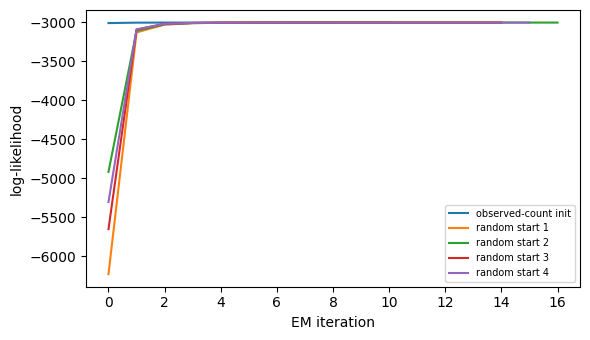

In [22]:
#9.3 run EM: from the observed-count tables, plus 4 random starts as a sanity check
rng = np.random.default_rng(0)
starts = {"observed-count init": fit_counts(X, ESS)}
for i in range(4):
    starts[f"random start {i + 1}"] = random_cpts(rng)

runs = {}
for name, init in starts.items():
    cp, hist = em(X, init, ess=ESS)
    runs[name] = (cp, hist)
summary = pd.DataFrame({k: {"iterations": len(h), "final_loglik": round(h[-1], 2)} for k, (c, h) in runs.items()}).T
print(summary)
best = max(runs, key=lambda k: runs[k][1][-1])
cpts_em, hist_em = runs[best]
print("\nusing:", best)

plt.figure(figsize=(6, 3.5))
for k, (c, h) in runs.items():
    plt.plot(h, label=k)
plt.xlabel("EM iteration"); plt.ylabel("log-likelihood"); plt.legend(fontsize=7); plt.tight_layout()
plt.savefig("figures/em_loglik.png", dpi=130); plt.show()

## 10. Probability calculation after EM
Everything below is computed from the EM-fitted network (`cpts_em`), which uses all 664 children.

In [23]:
#10.1 the anaemia table: EM vs the observed-count table
par = PAR["anaemia"]
idx = pd.MultiIndex.from_product([STATES[p] for p in par], names=par)
cnt, prob_obs, n_obs, used = cpt_counts("anaemia", par)        # section-8 counts on the same parents
anaemia_tab = pd.DataFrame({
    "n_children_with_label": n_obs.values,
    "P(anaemia)_observed": prob_obs["yes"].round(3).values,
    "P(anaemia)_EM": cpts_em["anaemia"][..., YES].reshape(-1).round(3),
}, index=idx)
print(f"{int((n_obs > 0).sum())} of {len(n_obs)} combinations have labelled children; "
      f"EM fills the remaining {int((n_obs == 0).sum())} from the structure (weakly, via the prior)")
anaemia_tab[anaemia_tab.n_children_with_label > 0].sort_values("n_children_with_label", ascending=False)

19 of 20 combinations have labelled children; EM fills the remaining 1 from the structure (weakly, via the prior)


n_children_with_label  \
ethnicity   food_security wic_child                          
NHWhite     secure        no                            67   
                          yes                           24   
NHBlack     secure        yes                           23   
OthHisp     secure        yes                           19   
Asian_Other secure        yes                           16   
OthHisp     insecure      yes                           14   
NHBlack     insecure      yes                           14   
NHWhite     insecure      yes                           10   
OthHisp     secure        no                            10   
MexAm       secure        yes                            9   
Asian_Other secure        no                             9   
MexAm       insecure      yes                            9   
            secure        no                             8   
NHWhite     insecure      no                             6   
Asian_Other insecure      yes                            5   
                          no                             3   
NHBlack     secure        no                             3   
OthHisp     insecure      no                             2   
MexAm       insecure      no                             1   

                                     P(anaemia)_observed  P(anaemia)_EM  
ethnicity   food_security wic_child                                      
NHWhite     secure        no                       0.030          0.034  
                          yes                      0.042          0.046  
NHBlack     secure        yes                      0.130          0.107  
OthHisp     secure        yes                      0.158          0.122  
Asian_Other secure        yes                      0.000          0.024  
OthHisp     insecure      yes                      0.214          0.135  
NHBlack     insecure      yes                      0.143          0.194  
NHWhite     insecure      yes                      0.000          0.033  
OthHisp     secure        no                       0.100          0.097  
MexAm       secure        yes                      0.000          0.030  
Asian_Other secure        no                       0.000          0.028  
MexAm       insecure      yes                      0.111          0.078  
            secure        no                       0.000          0.034  
NHWhite     insecure      no                       0.000          0.045  
Asian_Other insecure      yes                      0.200          0.099  
                          no                       0.000          0.050  
NHBlack     secure        no                       0.000          0.053  
OthHisp     insecure      no                       0.500          0.132  
MexAm       insecure      no                       0.000          0.061

In [24]:
#10.2 population probabilities: observed rows vs EM
J = joint(cpts_em)
def marg(node):                                     # P(node = each state) under the EM model
    return J.sum(axis=tuple(a for a in range(K) if a != AX[node]))

rows = []
for n in NODES_EM:
    obs = net[n].dropna().value_counts(normalize=True).reindex(STATES[n]).fillna(0)
    em_p = pd.Series(marg(n), index=STATES[n])
    for s in STATES[n]:
        rows.append({"node": n, "state": s, "observed_rows": round(obs[s], 3), "EM_all_children": round(em_p[s], 3)})
pd.DataFrame(rows).set_index(["node", "state"])

observed_rows  EM_all_children
node           state                                        
ethnicity      MexAm                  0.123            0.123
               OthHisp                0.154            0.154
               NHWhite                0.414            0.414
               NHBlack                0.158            0.158
               Asian_Other            0.151            0.151
parent_edu     low                    0.128            0.129
               mid                    0.509            0.510
               high                   0.363            0.361
income         below_poverty          0.277            0.275
               to_185pct              0.219            0.227
               above_185pct           0.504            0.497
wic_child      no                     0.436            0.444
               yes                    0.564            0.556
snap_past_year no                     0.558            0.563
               yes                    0.442            0.437
food_security  secure                 0.761            0.770
               insecure               0.239            0.230
anaemia        no                     0.929            0.938
               yes                    0.071            0.062

In [25]:
#10.3 P(anaemia) for each level of each factor: observed vs EM
labelled = net[net["anaemia"].notna()]
rows = []
for n in NODES_EM[:-1]:
    for s in STATES[n]:
        sub = labelled[labelled[n] == s]
        j2 = J.sum(axis=tuple(a for a in range(K) if a not in (AX[n], AX["anaemia"])))
        j2 = j2 if AX[n] < AX["anaemia"] else j2.T
        p_em = j2[STATES[n].index(s), YES] / j2[STATES[n].index(s)].sum()
        rows.append({"factor": n, "level": s, "n_labelled": len(sub),
                     "P(anaemia)_observed": round((sub["anaemia"] == "yes").mean(), 3) if len(sub) else np.nan,
                     "P(anaemia)_EM": round(float(p_em), 3)})
prev_em = marg("anaemia")[YES]
print(f"overall prevalence: observed {(labelled['anaemia'] == 'yes').mean():.3f} "
      f"(n={len(labelled)})  |  EM {prev_em:.3f} (reweighted to all {len(net)} children)")
pd.DataFrame(rows).set_index(["factor", "level"])

overall prevalence: observed 0.071 (n=340)  |  EM 0.062 (reweighted to all 664 children)


n_labelled  P(anaemia)_observed  P(anaemia)_EM
factor         level                                                        
ethnicity      MexAm                  38                0.026          0.043
               OthHisp                58                0.155          0.116
               NHWhite               140                0.029          0.039
               NHBlack                58                0.155          0.109
               Asian_Other            46                0.022          0.040
parent_edu     low                    42                0.024          0.065
               mid                   152                0.086          0.064
               high                  109                0.037          0.059
income         below_poverty          81                0.136          0.080
               to_185pct              65                0.031          0.069
               above_185pct          153                0.046          0.050
wic_child      no                    115                0.035          0.047
               yes                   148                0.101          0.075
snap_past_year no                    178                0.051          0.056
               yes                   139                0.086          0.071
food_security  secure                238                0.046          0.054
               insecure               79                0.127          0.091

In [26]:
#10.4 predict for one child (any answers can be left out)
def predict(**answers):
    row = np.full(K, -1)
    for n, s in answers.items():
        row[AX[n]] = STATES[n].index(s)
    return p_anaemia(J, row)

print("average child                 :", f"{predict():.1%}")
print("food insecure                 :", f"{predict(food_security='insecure'):.1%}")
print("NH Black, food insecure       :", f"{predict(ethnicity='NHBlack', food_security='insecure'):.1%}")
print("NH Black, secure, income low  :", f"{predict(ethnicity='NHBlack', food_security='secure', income='below_poverty'):.1%}")

# save the final tables
tidy = []
for n in NODES_EM:
    fam = family(n)
    parents = PAR[n]
    combos = list(pd.MultiIndex.from_product([STATES[p] for p in parents]).tolist()) if parents else [()]
    flat = cpts_em[n].reshape(-1, SH[AX[n]])
    for conf, vec in zip(combos, flat):
        conf = conf if isinstance(conf, tuple) else (conf,)
        for st, pv in zip(STATES[n], vec):
            tidy.append({"node": n, "parent_config": " & ".join(f"{p}={v}" for p, v in zip(parents, conf)) or "(none)",
                         "state": st, "P_EM": round(float(pv), 5)})
pd.DataFrame(tidy).to_csv("data/cpt_em.csv", index=False)
print("saved data/cpt_em.csv")

average child                 : 6.2%
food insecure                 : 9.1%
NH Black, food insecure       : 17.3%
NH Black, secure, income low  : 10.0%
saved data/cpt_em.csv


## 11. Does EM actually predict better?
Repeated 5-fold cross-validation on the children with a blood result. In each fold the test children's anaemia label is hidden from training (their other answers stay in). Compared: the section-8 count-based tables vs EM, at three prior strengths, against a "predict the average" baseline. The default `ESS = 10` was picked from this table, so its scores are slightly optimistic. **With only 24 positive cases the scores are noisy, so judge by the spread across repeats, not the third decimal.**

In [27]:
#11.1 cross-validation: counts-only vs EM, for three prior strengths
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss

lab_idx = np.where(X[:, AX["anaemia"]] >= 0)[0]
y_all = X[lab_idx, AX["anaemia"]]
folds = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0).split(lab_idx, y_all))
res = []
for ess in [2.0, 10.0, 30.0]:
    oof = {"counts": np.zeros((3, len(lab_idx))), "EM": np.zeros((3, len(lab_idx)))}
    for f, (tr, te) in enumerate(folds):
        Xtr = X.copy(); Xtr[lab_idx[te], AX["anaemia"]] = -1        # hide the test children's labels
        c_counts = fit_counts(Xtr, ess)
        c_em, _ = em(Xtr, c_counts, ess=ess, max_iter=200, tol=1e-5)
        for name, cp in [("counts", c_counts), ("EM", c_em)]:
            Jf = joint(cp)
            oof[name][f // 5, te] = [p_anaemia(Jf, X[lab_idx[i]]) for i in te]
    for name in ["counts", "EM"]:
        sc = np.array([[roc_auc_score(y_all, o), brier_score_loss(y_all, o), log_loss(y_all, o)] for o in oof[name]])
        res.append({"model": name, "prior_strength": ess,
                    **{k: f"{sc[:, i].mean():.3f} +/- {sc[:, i].std():.3f}" for i, k in enumerate(["AUC", "Brier", "log-loss"])}})
base = np.full(len(y_all), y_all.mean())
res.append({"model": "baseline (always the average)", "prior_strength": "-", "AUC": "0.500",
            "Brier": f"{brier_score_loss(y_all, base):.3f}", "log-loss": f"{log_loss(y_all, base):.3f}"})
pd.DataFrame(res).set_index(["model", "prior_strength"])

,,AUC,Brier,log-loss
model,prior_strength,,,
counts,2.0,0.589 +/- 0.007,0.068 +/- 0.001,0.272 +/- 0.002
EM,2.0,0.623 +/- 0.002,0.067 +/- 0.001,0.265 +/- 0.001
counts,10.0,0.606 +/- 0.020,0.066 +/- 0.000,0.256 +/- 0.001
EM,10.0,0.634 +/- 0.012,0.065 +/- 0.001,0.252 +/- 0.001
counts,30.0,0.618 +/- 0.018,0.065 +/- 0.000,0.253 +/- 0.001
EM,30.0,0.640 +/- 0.016,0.065 +/- 0.000,0.250 +/- 0.001
baseline (always the average),-,0.500,0.066,0.255


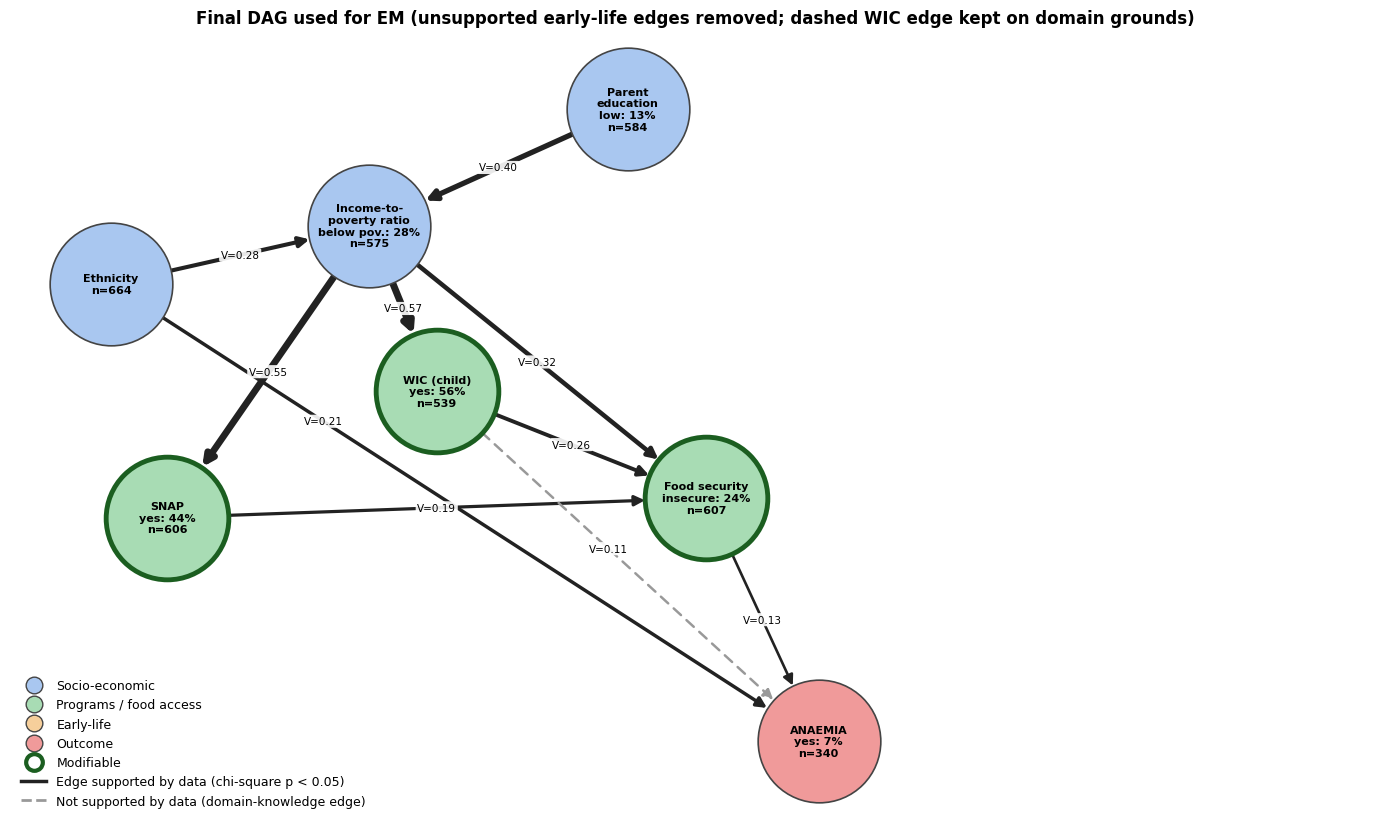

In [28]:
#11.2 final DAG (the structure EM used)
draw_dag(edge_list=EDGES_EM, path="figures/dag_final.png",
         title="Final DAG used for EM (unsupported early-life edges removed; dashed WIC edge kept on domain grounds)")